In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
df = pd.read_csv(r"C:\Users\Vinayak\OneDrive\Desktop\ML_lab\StudentsPerformance.csv")

In [4]:
print("========== DATASET ==========")
df

========== DATASET ==========


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [5]:
print("========== DATASET SHAPE ==========")
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

========== DATASET SHAPE ==========
Rows : 1000
Columns : 8


In [6]:
print("========== DATA TYPES ==========")
print(df.dtypes)

========== DATA TYPES ==========
gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object


In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(exclude=np.number).columns

# Fill numerical columns with mean
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].mean())

# Fill categorical columns with mode
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

print("Cleaning Completed")

Cleaning Completed


In [8]:
print("========== AFTER CLEANING ==========")
print(df.isnull().sum())

========== AFTER CLEANING ==========
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [9]:
print("========== SUMMARY STATISTICS ==========")
df.describe(include="all")

========== SUMMARY STATISTICS ==========


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


In [10]:
print("========== NUMERICAL SUMMARY ==========")

for column in numeric_columns:
    print("\nColumn :", column)
    print("Mean :", np.mean(df[column]))
    print("Median :", np.median(df[column]))
    print("Standard Deviation :", np.std(df[column]))

========== NUMERICAL SUMMARY ==========

Column : math score
Mean : 66.089
Median : 66.0
Standard Deviation : 15.155496659628165

Column : reading score
Mean : 69.169
Median : 70.0
Standard Deviation : 14.59289001534652

Column : writing score
Mean : 68.054
Median : 69.0
Standard Deviation : 15.188057281956757


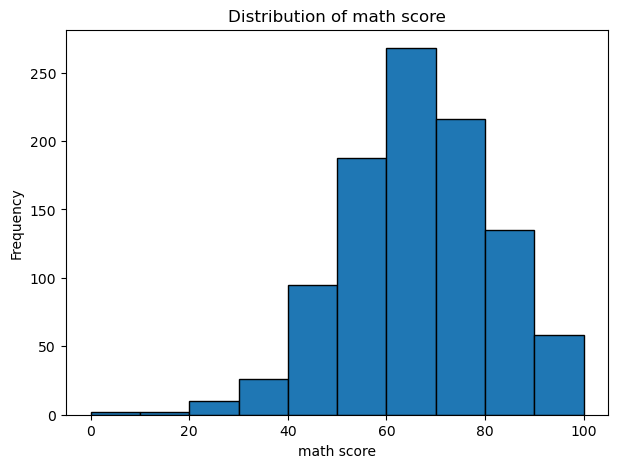

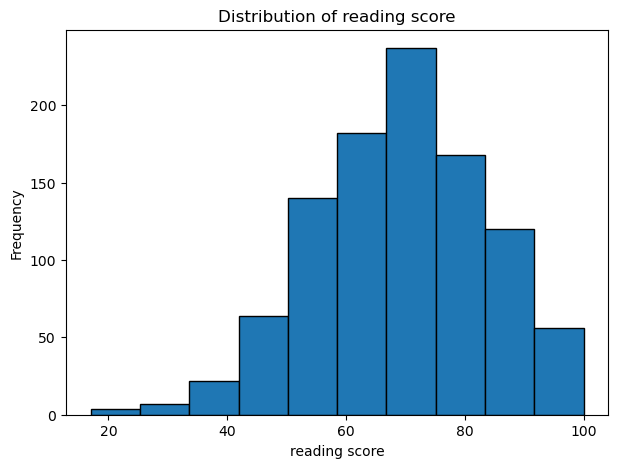

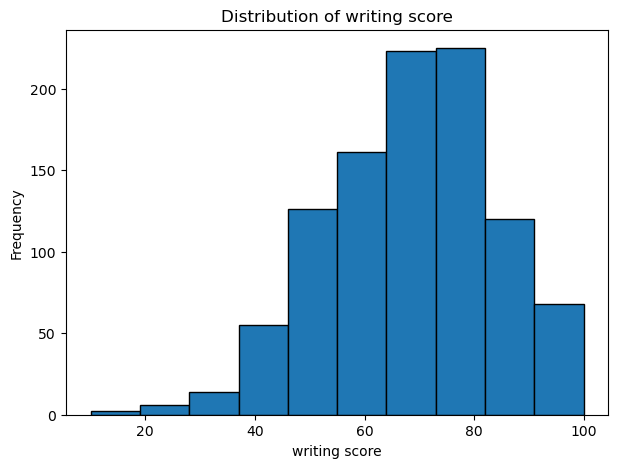

In [11]:
for column in numeric_columns:
    plt.figure(figsize=(7,5))
    plt.hist(df[column], bins=10, edgecolor='black')
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

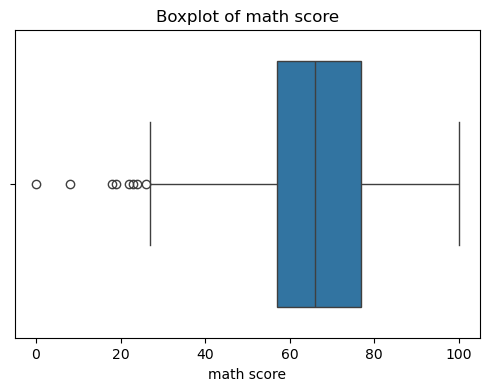

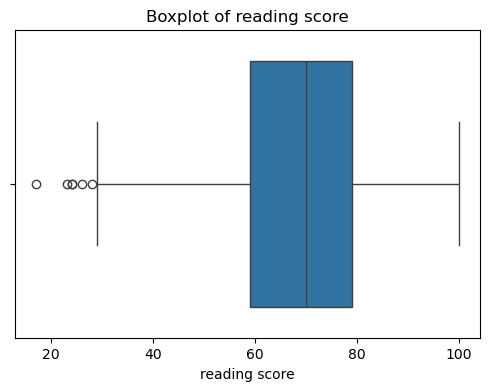

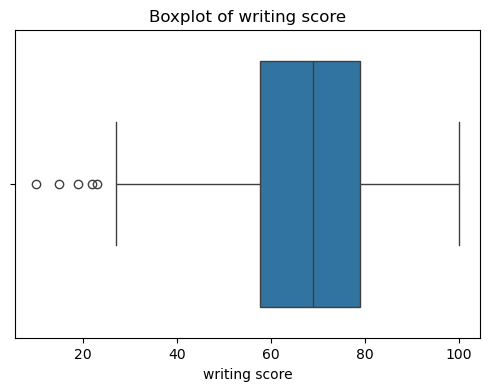

In [12]:
for column in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

In [13]:
correlation = df[numeric_columns].corr()

print(correlation)

               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


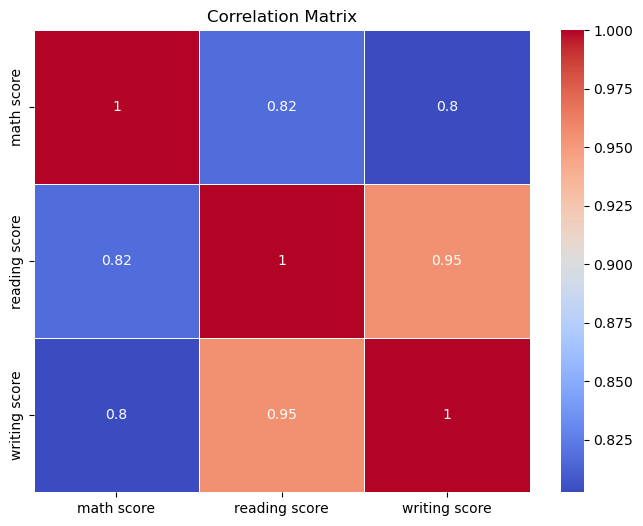

In [14]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

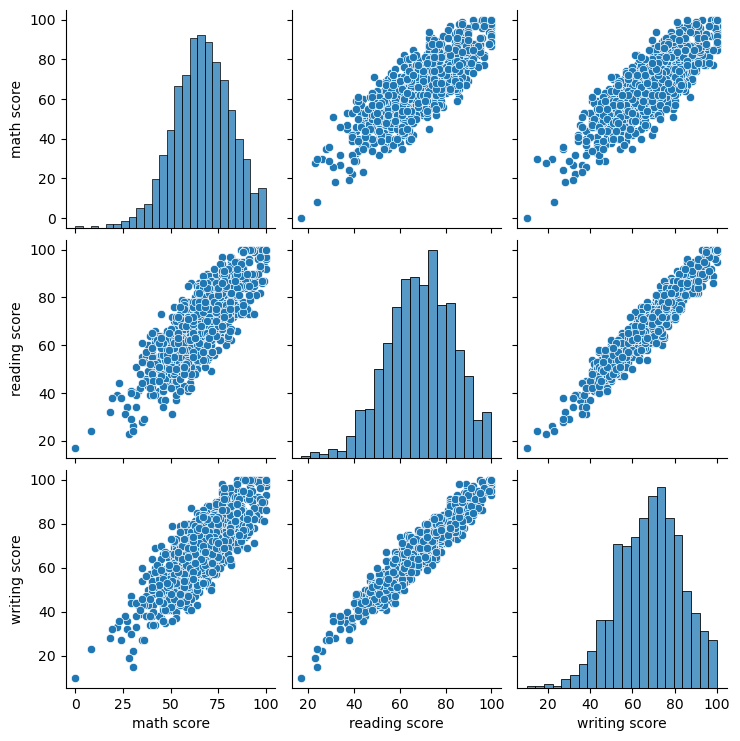

In [15]:
sns.pairplot(df[numeric_columns])
plt.show()

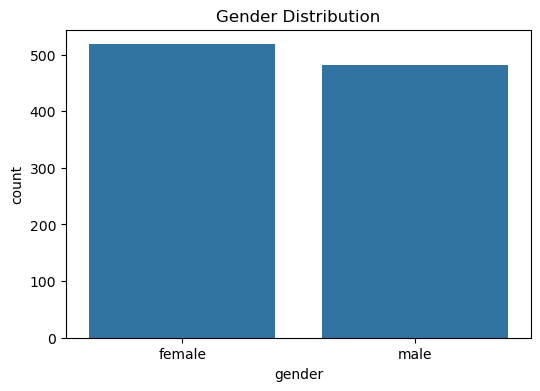

In [16]:
plt.figure(figsize=(6,4))

sns.countplot(x="gender", data=df)

plt.title("Gender Distribution")
plt.show()

In [17]:
df.groupby("gender")[["math score","reading score","writing score"]].mean()

,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


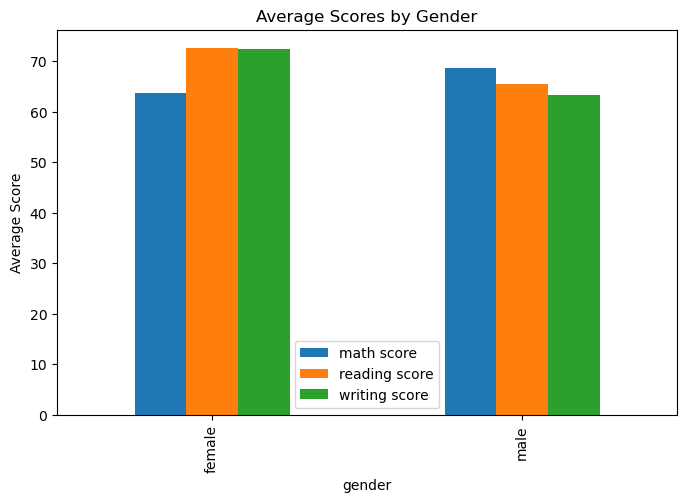

In [18]:
df.groupby("gender")[["math score","reading score","writing score"]].mean().plot(kind="bar", figsize=(8,5))

plt.ylabel("Average Score")
plt.title("Average Scores by Gender")

plt.show()

In [19]:
df.groupby("parental level of education")[["math score","reading score","writing score"]].mean()

,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


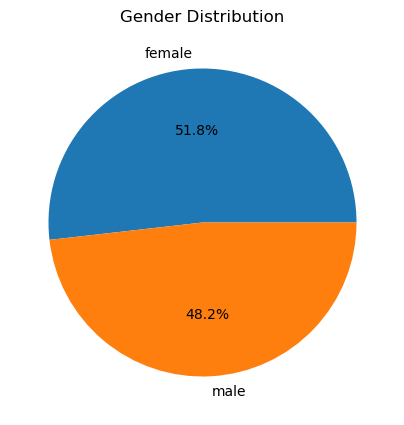

In [20]:
df["gender"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(5,5)
)

plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

In [21]:
df.to_csv("StudentsPerformance_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
